# TP1 — Détection de fake news avec un PLM

Notebook de synthèse. Il ne relance pas les entraînements (ça prend jusqu'à ~15 min pour la partie C sur GPU), il charge les résultats déjà calculés par les scripts dans `src/` et les présente dans l'ordre.

Pour tout reproduire depuis zéro : voir `README.md` (`uv run python src/data.py`, puis `baseline.py`, `frozen_plm.py`, `finetune_plm.py`, `bonus_llm.py`, `compare.py`, dans cet ordre).

## 1. Jeu de données

Dataset choisi : **WELFake** (option C), via Hugging Face (`davanstrien/WELFake`). ~72k articles en anglais, fusion de 4 sources, labellisé fake/real.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

train_df = pd.read_parquet('data/train.parquet')
val_df = pd.read_parquet('data/val.parquet')
test_df = pd.read_parquet('data/test.parquet')

print(f'train: {len(train_df)}  val: {len(val_df)}  test: {len(test_df)}')
train_df.head(3)

train: 50904  val: 6363  test: 6364


,full_text,label
0,"Podesta in Leaked E-mail: ""Dump Those Emails"" ...",0
1,Fox News’s Convention Moment Overshadowed by S...,1
2,Egypt FM to head to Ethiopia after Nile dam ta...,1


In [2]:
label_names = {0: 'fake', 1: 'real'}
train_df['label'].map(label_names).value_counts()

label
real    27832
fake    23072
Name: count, dtype: int64

Les classes sont légèrement déséquilibrées (environ 55 % de real contre 45 % de fake). Le déséquilibre reste modéré donc l'accuracy garde du sens, mais je suis aussi le F1 en parallèle pour ne pas rater une faiblesse sur la classe minoritaire.

## 2. Un problème détecté dans les labels du dataset

En regardant les premiers résultats du bonus (LLM prompté), j'ai eu un score d'accuracy de seulement 16,5 %, très en dessous du hasard (~50 % sur 2 classes). En creusant, j'ai découvert que les labels du dataset tel que publié sur Hugging Face sont inversés par rapport à leur propre description (`ClassLabel(names=["fake", "real"])`).

Preuve : les vrais articles de presse citent presque toujours leur source, par exemple la mention « (Reuters) ». Je compte combien d'articles la contiennent, par label brut **avant correction** :

In [3]:
from datasets import load_dataset

raw = load_dataset('davanstrien/WELFake', split='train').to_pandas()
raw['has_reuters'] = raw['text'].str.contains(r'\(Reuters\)', regex=True, na=False)
raw.groupby('label')['has_reuters'].agg(['sum', 'count', 'mean'])

,sum,count,mean
label,,,
0,21266,35028,0.607114
1,16,37106,0.000431


61 % des articles label=0 contiennent « (Reuters) », contre 0,05 % pour label=1. Un écart pareil ne peut pas être un hasard : le label 0 (que le dataset appelle "fake") correspond en réalité à du contenu réel, et le label 1 ("real") à du contenu fake. J'ai confirmé ça à la main en lisant plusieurs articles de chaque label, puis j'ai inversé le label dans `src/data.py` (`df['label'] = 1 - df['label']`) avant de lancer quoi que ce soit d'autre. Toutes les données ci-dessous (`data/*.parquet`) utilisent déjà la version corrigée.

## 3. Approche A — Baseline (TF-IDF + régression logistique)

In [4]:
metrics = json.load(open('results/metrics.json'))
metrics['A_baseline']

{'accuracy': 0.9550597108736644,
 'f1': 0.9589434395635946,
 'train_time_seconds': 52.1122641999973,
 'approach': 'A - TF-IDF + Logistic Regression'}

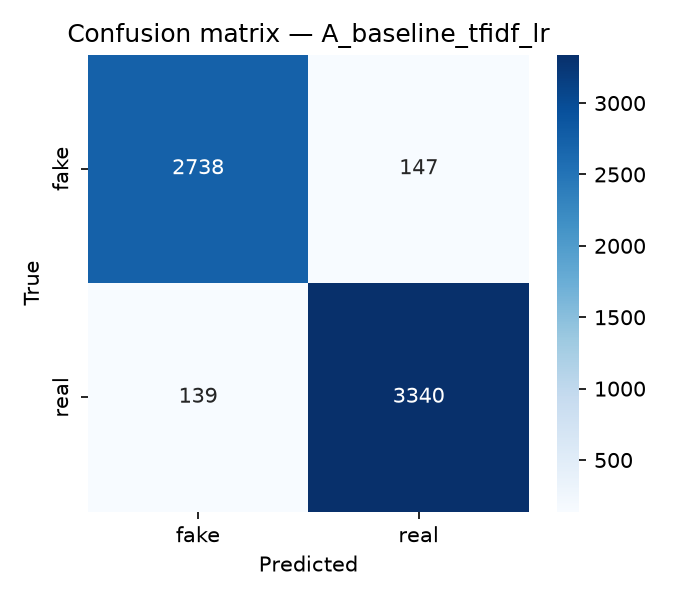

In [5]:
display(Image('results/confusion_matrices/A_baseline_tfidf_lr.png'))

## 4. Approche B — PLM gelé (DistilBERT comme extracteur de features)

In [6]:
metrics['B_frozen_plm']

{'accuracy': 0.9453174104336896,
 'f1': 0.9502145922746781,
 'train_embedding_extraction_time_seconds': 175.80708439997397,
 'approach': 'B - Frozen DistilBERT (feature extractor) + Logistic Regression',
 'peak_gpu_memory_mb': 576.83203125}

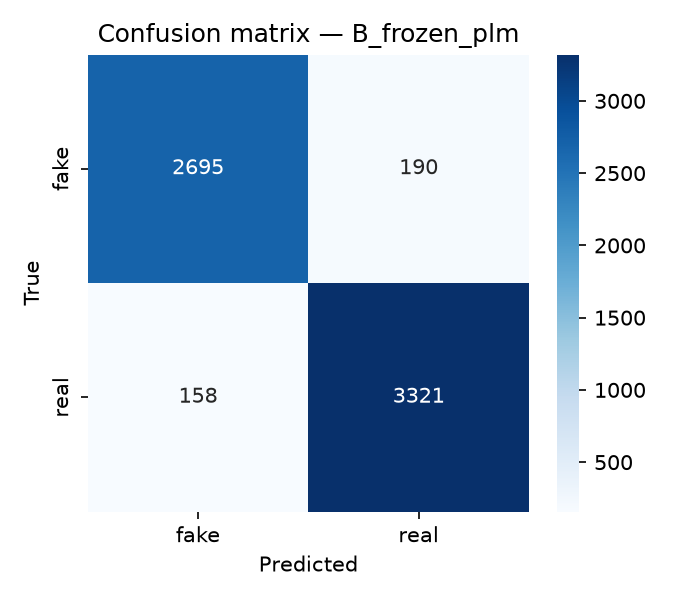

In [7]:
display(Image('results/confusion_matrices/B_frozen_plm.png'))

Ici il n'y a pas de gain par rapport à la baseline : le PLM gelé fait même un peu moins bien. Sur ce dataset, fake/real se distingue surtout par des marqueurs de style très visibles que le TF-IDF capte déjà directement ; le mean-pooling des embeddings sur un texte tronqué dilue ce signal sans rien apporter de plus.

## 5. Approche C — PLM fine-tuné (DistilBERT + HF Trainer)

In [8]:
metrics['C_finetuned_plm']

{'accuracy': 0.9938717787554997,
 'f1': 0.9943957465153039,
 'train_time_seconds': 880.7212863999885,
 'approach': 'C - Fine-tuned DistilBERT (HF Trainer)',
 'peak_gpu_memory_mb': 1718.56982421875}

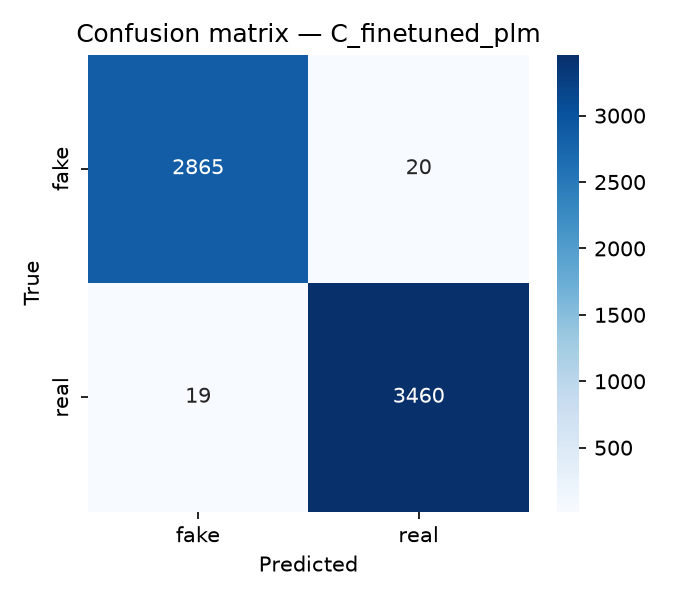

In [9]:
display(Image('results/confusion_matrices/C_finetuned_plm.png'))

Là il y a un vrai gain : +4,86 points d'accuracy et +4,42 points de F1 par rapport au PLM gelé, pour un coût d'entraînement ponctuel d'environ 15 minutes sur la RTX 4070.

## 6. Bonus — LLM prompté (Gemini flash-lite, few-shot)

In [10]:
metrics['Bonus_llm_prompted']

{'accuracy': 0.835,
 'f1': 0.8674698795180723,
 'api_call_time_seconds': 3036.664886499988,
 'n_examples': 200,
 'approach': 'Bonus - gemini-flash-lite-latest few-shot prompting'}

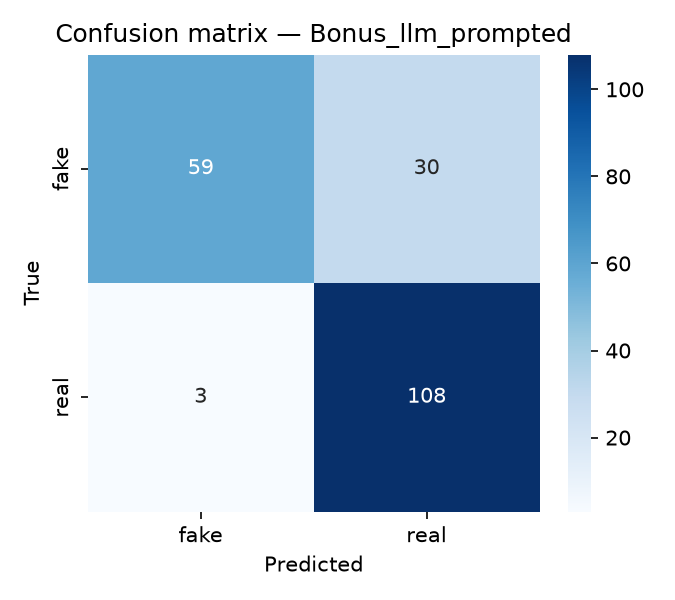

In [11]:
display(Image('results/confusion_matrices/Bonus_llm_prompted.png'))

83,5 % d'accuracy sur 200 exemples du test set, nettement en dessous du PLM fine-tuné. Un autre modèle ou une autre clé API aurait sans doute fait un peu mieux, mais le coût (payant à l'usage, plus lent, moins précis) n'en vaut pas la peine face à un modèle qu'on entraîne une seule fois soi-même.

## 7. Comparaison finale

In [12]:
pd.read_csv('results/comparison_table.csv')

,approach,accuracy,f1,time_seconds,peak_gpu_memory_mb
0,A - TF-IDF + Logistic Regression,0.9551,0.9589,52.11,NaN
1,B - Frozen DistilBERT (feature extractor) + Lo...,0.9453,0.9502,175.81,576.8
2,C - Fine-tuned DistilBERT (HF Trainer),0.9939,0.9944,880.72,1718.6
3,Bonus - gemini-flash-lite-latest few-shot prom...,0.8350,0.8675,3036.66,NaN


## 8. Décision

Je retiens le **PLM fine-tuné (DistilBERT, approche C)** : 99,39 % d'accuracy et 0,994 de F1, largement devant les 3 autres approches. Latence minimale à l'inférence (pas d'appel réseau, pas de limite de débit), coût d'infrastructure faible (modèle léger, utilisable même sur CPU), pour un coût d'entraînement ponctuel raisonnable (~15 min GPU).